data type specific to pandas

series
dataframe (data.dataframe for new df)

In [2]:
import pandas as pd
df = pd.read_csv('president_heights1.csv')


In [3]:
df.head


<bound method NDFrame.head of     order                    name  height(cm)
0      16         Abraham Lincoln       193.0
1       7          Andrew Jackson       185.0
2      17          Andrew Johnson       178.0
3      44            Barack Obama         NaN
4      23       Benjamin Harrison       168.0
5      42            Bill Clinton       188.0
6      30         Calvin Coolidge       178.0
7      21       Chester A. Arthur       183.0
8      34    Dwight D. Eisenhower       179.0
9      32   Franklin D. Roosevelt       188.0
10     14         Franklin Pierce         NaN
11     41       George H. W. Bush       188.0
12     43          George W. Bush       182.0
13      1       George Washington       189.0
14     38             Gerald Ford         NaN
15     33         Harry S. Truman       175.0
16     31          Herbert Hoover       182.0
17     20       James A. Garfield         NaN
18     15          James Buchanan       183.0
19     11           James K. Polk       173.0
20  

In [4]:
df.shape


(42, 3)

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order       42 non-null     int64  
 1   name        42 non-null     str    
 2   height(cm)  37 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 1.7 KB


In [6]:
df.describe()


,order,height(cm)
count,42.000000,37.000000
mean,22.476190,179.378378
std,13.152461,7.361127
min,1.000000,163.000000
25%,11.250000,173.000000
50%,22.000000,180.000000
75%,33.750000,183.000000
max,44.000000,193.000000


In [7]:
df.head(5)


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
3,44,Barack Obama,NaN
4,23,Benjamin Harrison,168.0


In [8]:
df.iloc[0:5]


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
3,44,Barack Obama,NaN
4,23,Benjamin Harrison,168.0


In [9]:
df.loc[3]


order                   44
name          Barack Obama
height(cm)             NaN
Name: 3, dtype: object

In [10]:
df.iloc[[0,9,5,8]]


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
9,32,Franklin D. Roosevelt,188.0
5,42,Bill Clinton,188.0
8,34,Dwight D. Eisenhower,179.0


In [11]:
df.iloc[[0,4,5,5,6,8,4],[1,2]]


,name,height(cm)
0,Abraham Lincoln,193.0
4,Benjamin Harrison,168.0
5,Bill Clinton,188.0
5,Bill Clinton,188.0
6,Calvin Coolidge,178.0
8,Dwight D. Eisenhower,179.0
4,Benjamin Harrison,168.0


In [12]:
df.iloc[:,[1,2]]


,name,height(cm)
0,Abraham Lincoln,193.0
1,Andrew Jackson,185.0
2,Andrew Johnson,178.0
3,Barack Obama,NaN
4,Benjamin Harrison,168.0
5,Bill Clinton,188.0
6,Calvin Coolidge,178.0
7,Chester A. Arthur,183.0
8,Dwight D. Eisenhower,179.0
9,Franklin D. Roosevelt,188.0


In [13]:
df.iloc[:20:2]


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
2,17,Andrew Johnson,178.0
4,23,Benjamin Harrison,168.0
6,30,Calvin Coolidge,178.0
8,34,Dwight D. Eisenhower,179.0
10,14,Franklin Pierce,NaN
12,43,George W. Bush,182.0
14,38,Gerald Ford,NaN
16,31,Herbert Hoover,182.0
18,15,James Buchanan,183.0


In [14]:
df[df['height(cm)'].isnull()]


,order,name,height(cm)
3,44,Barack Obama,NaN
10,14,Franklin Pierce,NaN
14,38,Gerald Ford,NaN
17,20,James A. Garfield,NaN
24,35,John F. Kennedy,NaN


In [15]:
df[df['height(cm)'].notnull()]


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
4,23,Benjamin Harrison,168.0
5,42,Bill Clinton,188.0
6,30,Calvin Coolidge,178.0
7,21,Chester A. Arthur,183.0
8,34,Dwight D. Eisenhower,179.0
9,32,Franklin D. Roosevelt,188.0
11,41,George H. W. Bush,188.0


In [16]:
clean_df = df.dropna()
print(f" DF : {df.shape}")
print(f" Clean_DF : {clean_df.shape}")


 DF : (42, 3)
 Clean_DF : (37, 3)


In [17]:
Ffill = df.ffill()
print(f" Shape : {Ffill.shape}")
print(Ffill[df['height(cm)'].isnull()])


 Shape : (42, 3)
    order               name  height(cm)
3      44       Barack Obama       178.0
10     14    Franklin Pierce       188.0
14     38        Gerald Ford       189.0
17     20  James A. Garfield       182.0
24     35    John F. Kennedy       170.0


In [18]:
early_tall = df[(df['height(cm)'] > 185) & (df['order'] <= 20)]
early_tall


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
13,1,George Washington,189.0
34,3,Thomas Jefferson,189.0


In [19]:
max_df = df[df['height(cm)'] == df['height(cm)'].max()]
max_df


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
27,36,Lyndon B. Johnson,193.0


In [20]:
tall3 = df.nlargest(3,'height(cm)')
tall3


,order,name,height(cm)
0,16,Abraham Lincoln,193.0
27,36,Lyndon B. Johnson,193.0
13,1,George Washington,189.0


<Axes: title={'center': 'Top 5 Tallest People'}, xlabel='Name', ylabel='Height (cm)'>

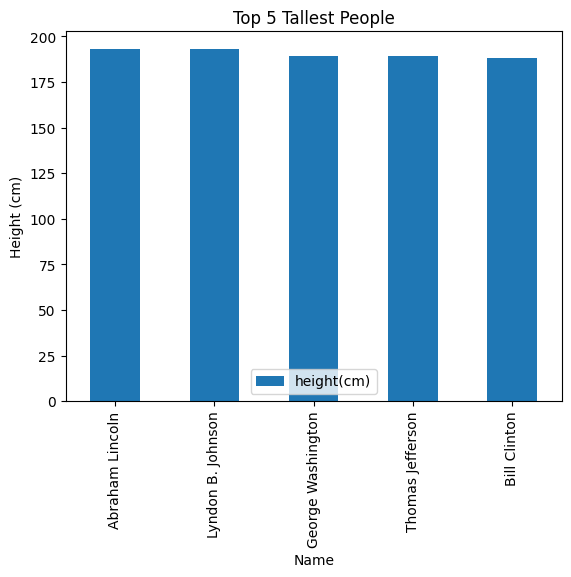

In [21]:
top5 = df.nlargest(5,'height(cm)')
top5.plot.bar(x='name', y='height(cm)', title='Top 5 Tallest People', ylabel='Height (cm)', xlabel='Name')


<Axes: title={'center': 'Height Distribution'}, ylabel='Frequency'>

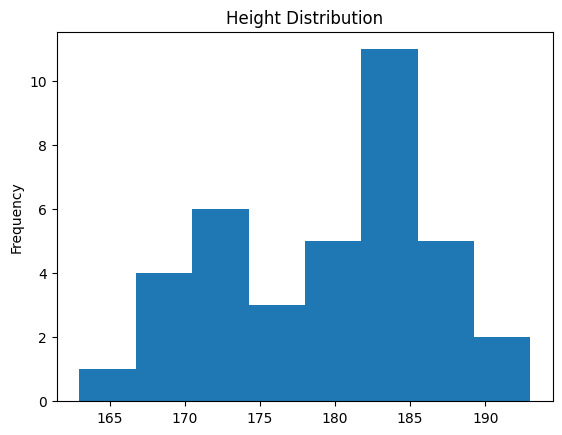

In [ ]:
df['height(cm)'].plot.hist(bins=8, title='Height Distribution')


<Axes: ylabel='Frequency'>

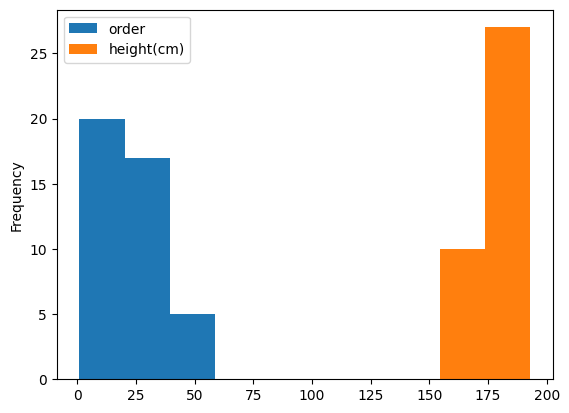

In [ ]:
df.plot.hist(bins=10)


<Axes: >

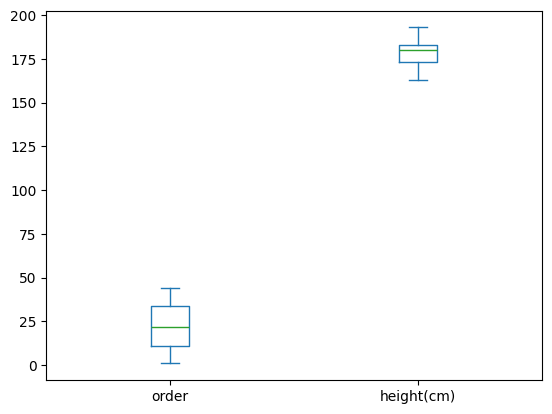

In [ ]:
df.plot.box()


<Axes: >

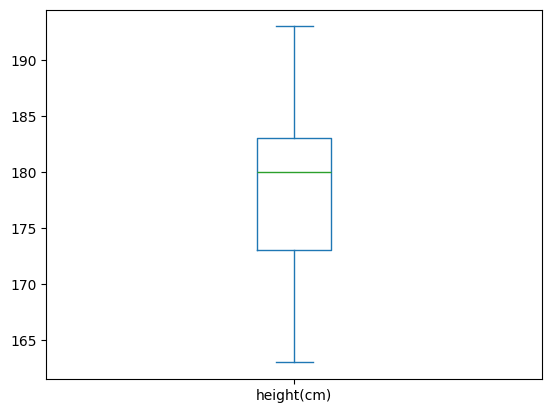

In [ ]:
df['height(cm)'].plot.box()


<Axes: >

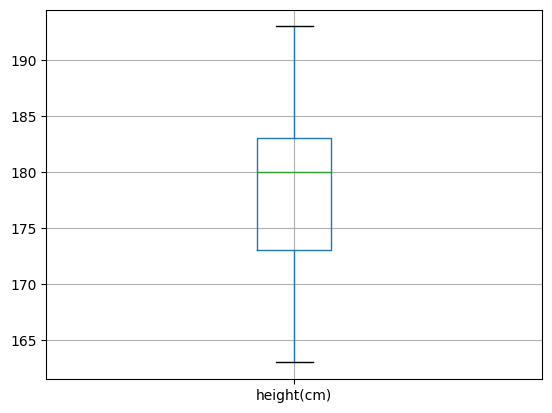

In [ ]:
df.boxplot(column='height(cm)')


<Axes: xlabel='order', ylabel='height(cm)'>

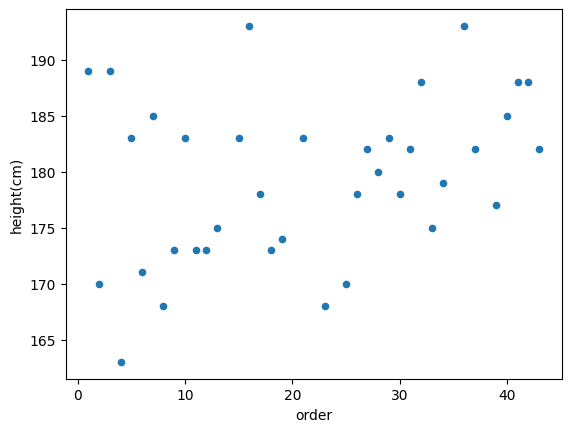

In [31]:
df.plot.scatter(x='order',y='height(cm)')


In [38]:
df1 = df.dropna()
df1['era'] = pd.cut(df1['order'], bins=[0, 15, 30 ,45], labels=['Early era', 'Middle era', 'Modern era'])
df1.head()


,order,name,height(cm),era
0,16,Abraham Lincoln,193.0,Middle era
1,7,Andrew Jackson,185.0,Early era
2,17,Andrew Johnson,178.0,Middle era
4,23,Benjamin Harrison,168.0,Middle era
5,42,Bill Clinton,188.0,Modern era


In [ ]:
df_mult= df1.set_index(['era', 'name']).sort_index()
df_mult.head(40)


order  height(cm)
era        name                                     
Early era  Andrew Jackson              7       185.0
           George Washington           1       189.0
           James Buchanan             15       183.0
           James K. Polk              11       173.0
           James Madison               4       163.0
           James Monroe                5       183.0
           John Adams                  2       170.0
           John Quincy Adams           6       171.0
           John Tyler                 10       183.0
           Martin Van Buren            8       168.0
           Millard Fillmore           13       175.0
           Thomas Jefferson            3       189.0
           William Henry Harrison      9       173.0
           Zachary Taylor             12       173.0
Middle era Abraham Lincoln            16       193.0
           Andrew Johnson             17       178.0
           Benjamin Harrison          23       168.0
           Calvin Coolidge            30       178.0
           Chester A. Arthur          21       183.0
           Rutherford B. Hayes        19       174.0
           Theodore Roosevelt         26       178.0
           Ulysses S. Grant           18       173.0
           Warren G. Harding          29       183.0
           William Howard Taft        27       182.0
           William McKinley           25       170.0
           Woodrow Wilson             28       180.0
Modern era Bill Clinton               42       188.0
           Dwight D. Eisenhower       34       179.0
           Franklin D. Roosevelt      32       188.0
           George H. W. Bush          41       188.0
           George W. Bush             43       182.0
           Harry S. Truman            33       175.0
           Herbert Hoover             31       182.0
           Jimmy Carter               39       177.0
           Lyndon B. Johnson          36       193.0
           Richard Nixon              37       182.0
           Ronald Reagan              40       185.0

In [ ]:
df_mult.head()


order  height(cm)
era       name                                
Early era Andrew Jackson         7       185.0
          George Washington      1       189.0
          James Buchanan        15       183.0
          James K. Polk         11       173.0
          James Madison          4       163.0

In [ ]:
# Reshape the president data into one row per president and measurement
melted = pd.melt(
    df,
    id_vars=['order', 'name'],
    value_vars=['height(cm)'],
    var_name='metric',
    value_name='value'
)
melted.head()


,order,name,metric,value
0,16,Abraham Lincoln,height(cm),193.0
1,7,Andrew Jackson,height(cm),185.0
2,17,Andrew Johnson,height(cm),178.0
3,44,Barack Obama,height(cm),NaN
4,23,Benjamin Harrison,height(cm),168.0


SyntaxError: invalid syntax. Perhaps you forgot a comma? (3789282207.py, line 1)